# Comparación observacional: DESI DR2 y Pantheon+

Primera implementación, 27 octubre 2026. Reutiliza los modelos del core. Los ejemplos añaden **materia conservada** al sector oscuro: es una hipótesis explícita. Parámetros del fluido fijos; se ajustan $\Omega_m$ y $H_0r_d$, perfilando $M$. No son restricciones finales ni una comparación de evidencias bayesianas.

In [ ]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/models.py").exists() or (p / "cosmo_singularities/src/models.py").exists())
if not (ROOT / "src/models.py").exists():
    ROOT = ROOT / "cosmo_singularities"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.models import BarotropicPowerDiffusionParams, BarotropicPowerDiffusionModel
from src.observations import CoreBackground, load_desi_dr2, load_pantheon_plus, joint_chi2, fit_background


## Cargar los catálogos locales

13 datos BAO y 1580 entradas SN seleccionadas de 1701 originales. Se conservan las covarianzas completas. Se excluyen calibradores y se usa $z_{HD}>0.01$. No se utiliza `MU_SH0ES`.

In [ ]:
bao = load_desi_dr2()
sn = load_pantheon_plus()
print("BAO:", len(bao.y), "SN:", len(sn.y))

## Un modelo del core y sus observables

`omega_m=0` recupera el fluido único. Para la extensión con materia, la evolución $\rho(a)$ se conserva porque $H$ cancela en continuidad. $H_0=70$ y $r_d=147$ aquí son valores de ejemplo, no medidas.

In [ ]:
params = BarotropicPowerDiffusionParams(omega=-1.2, alpha=4.0, beta=-1.0, rho0=1.0)
core = BarotropicPowerDiffusionModel(params)
background = CoreBackground(core, H0=70.0, omega_m=0.3)
d = background.distances(2.5)
z = [0.1, 0.5, 1.0, 2.0]
display(pd.DataFrame({"z": z, "E": background.E(z), "DM_Mpc": d.DM(z), "DH_Mpc": d.DH(z), "DL_Mpc": d.DL(z)}))
display(joint_chi2(background, rd=147.0, bao=bao, sn=sn))

## Resultados ya calculados

Se utilizan dos inicios de optimización por caso y se comprueba el efecto de duplicar la malla de distancias. El control LCDM también usa el core: $\omega=-1$, $\alpha=0$. Los otros ejemplos fijan $\omega=-1.2$, con o sin difusión. No se ha ajustado todavía todo el espacio $(\omega,\bar\alpha,\beta)$.

In [ ]:
results_path = sorted((ROOT / "data/observations/results").glob("*/fit_results.json"))[-1]
results = json.loads(results_path.read_text())
table = pd.DataFrame([{ "modelo":name, "Omega_m":r["parameters"][0], "H0_rd_km_s":r["parameters"][1], "chi2":r["chi2"], "chi2_BAO":r["chi2_bao"], "chi2_SN":r["chi2_sn"], "M_profile":r["M_profile"], "en_frontera":any(r["at_bound"])} for name,r in results["results"].items()])
display(table)

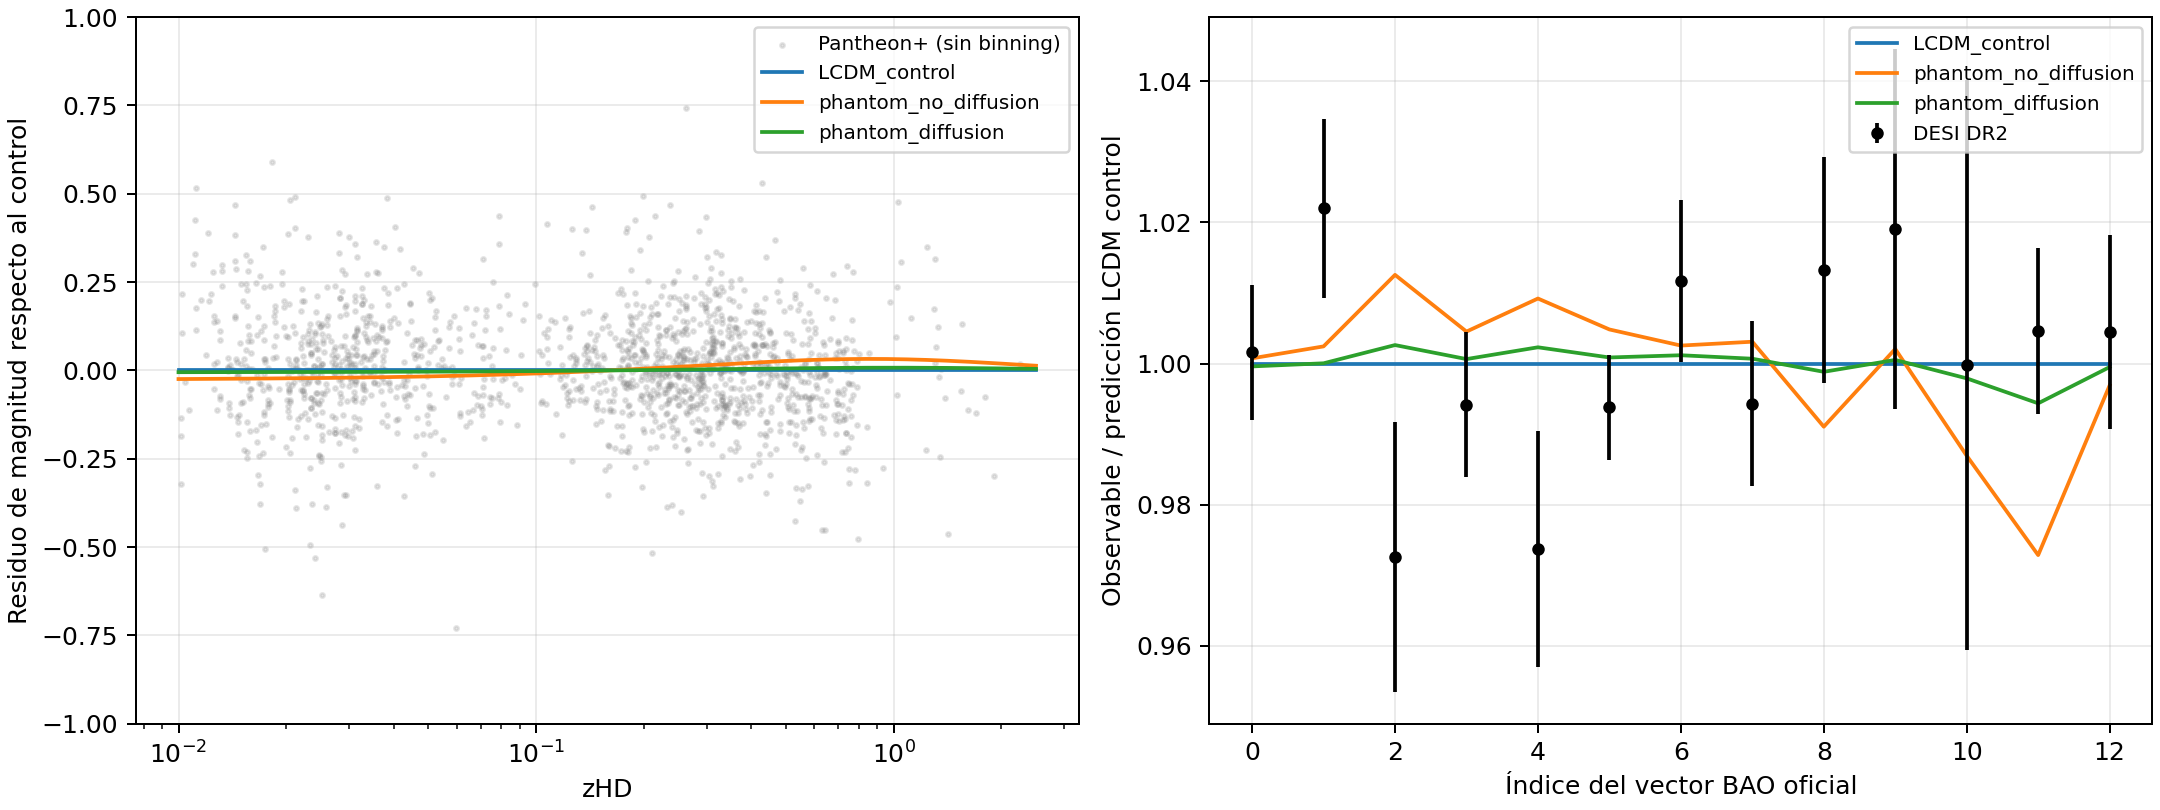

In [ ]:
display(Image(filename=str(results_path.parent / "comparison.png")))

Las barras BAO sólo muestran errores diagonales para visualizar; el ajuste usa la matriz completa. El panel SN usa magnitudes sin agrupar, con rango visual limitado a ±1 mag; el likelihood no elimina puntos por residuo.

## Repetir o modificar el ajuste

La factoría debe retornar `(CoreBackground, rd_en_Mpc)`. No variar simultáneamente $H_0$ y $r_d$ sin una calibración adicional: estos datos sólo identifican su producto. El código rechaza ramas sin extensión física hasta el redshift requerido.

In [ ]:
from scripts.compare_observations import factory
# Ejecutar cuando quieras repetir el ajuste:
# fitted = fit_background(lambda theta: factory("phantom_diffusion", theta),
#     starts=[[0.3, 10000], [0.4, 10500]], bounds=[(0.05, 0.6), (7000, 13000)],
#     bao=bao, sn=sn)
# display(fitted)

## Fuentes y siguiente etapa

- [DESI: productos cosmológicos oficiales](https://data.desi.lbl.gov/public/papers/y3/bao-cosmo-params/README.html).
- [Pantheon+: datos y covarianzas](https://github.com/PantheonPlusSH0ES/DataRelease/tree/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR).
- `docs/OBSERVACIONES.md`: hipótesis, derivaciones, unidades, cortes y límites.

Próximo paso: ajustar parámetros del sector oscuro con priors explícitos y cuantificar incertidumbres/degeneraciones. La compatibilidad termodinámica se debe evaluar separadamente. No hay CMB, perturbaciones, MCMC ni incertidumbres posteriores en esta primera versión.